# 02 · Software Defect Prediction — Feature Work and a Neural Network

**Question.** Can static code metrics predict whether a software module contains a defect?

**Data.** 101,763 modules, 21 numeric code metrics (Halstead and McCabe complexity measures, line counts);
22.7% of modules are defective.

**Approach.** Exploratory analysis → feature experiments (log transform, formula checks, missing-value flag) →
a Keras multilayer perceptron with regularization, early stopping and checkpointing, scored by ROC-AUC.

**Key findings.**

* **Disguised missing values.** 7,692 modules (7.6%) have *every* Halstead metric equal to zero — these are
  unfilled values, not real zeros. Their defect rate is **47.8% against 20.6%** for the rest.
* **Honest ceiling.** A baseline network reaches ROC-AUC 0.7908; all feature and regularization work brings it to
  **0.7934** (+0.0026). The metrics describe code size and branching, not meaning, so the task itself caps
  what any model can extract.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow info logs

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

RANDOM_STATE = 12345

## 1. Loading and inspecting the data

In [2]:
data = pd.read_csv('../data/software_defects_train.csv')
print('shape:', data.shape)
data.head()

shape: (101763, 23)


,id,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,b,t,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,0,22.0,3.0,1.0,2.0,60.0,278.63,0.06,19.56,14.25,5448.79,0.09,302.71,17,1,1,0,16.0,9.0,38.0,22.0,5.0,False
1,1,14.0,2.0,1.0,2.0,32.0,151.27,0.14,7.00,21.11,936.71,0.05,52.04,11,0,1,0,11.0,11.0,18.0,14.0,3.0,False
2,2,11.0,2.0,1.0,2.0,45.0,197.65,0.11,8.05,22.76,1754.01,0.07,97.45,8,0,1,0,12.0,11.0,28.0,17.0,3.0,False
3,3,8.0,1.0,1.0,1.0,23.0,94.01,0.19,5.25,17.86,473.66,0.03,26.31,4,0,2,0,8.0,6.0,16.0,7.0,1.0,True
4,4,11.0,2.0,1.0,2.0,17.0,60.94,0.18,5.63,12.44,365.67,0.02,20.31,7,0,2,0,7.0,6.0,10.0,10.0,3.0,False


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 101763 entries, 0 to 101762
Data columns (total 23 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 101763 non-null  int64  
 1   loc                101763 non-null  float64
 2   v(g)               101763 non-null  float64
 3   ev(g)              101763 non-null  float64
 4   iv(g)              101763 non-null  float64
 5   n                  101763 non-null  float64
 6   v                  101763 non-null  float64
 7   l                  101763 non-null  float64
 8   d                  101763 non-null  float64
 9   i                  101763 non-null  float64
 10  e                  101763 non-null  float64
 11  b                  101763 non-null  float64
 12  t                  101763 non-null  float64
 13  lOCode             101763 non-null  int64  
 14  lOComment          101763 non-null  int64  
 15  lOBlank            101763 non-null  int64  
 16  locCodeAndCom

In [4]:
print('missing values:', data.isna().sum().sum())
print('duplicates (ignoring id):', data.drop(columns='id').duplicated().sum())
data.describe().T.round(2)

missing values: 0
duplicates (ignoring id): 0


,count,mean,std,min,25%,50%,75%,max
id,101763.0,50881.00,29376.59,0.0,25440.50,50881.00,76321.50,101762.00
loc,101763.0,37.35,54.60,1.0,13.00,22.00,42.00,3442.00
v(g),101763.0,5.49,7.90,1.0,2.00,3.00,6.00,404.00
ev(g),101763.0,2.85,4.63,1.0,1.00,1.00,3.00,165.00
iv(g),101763.0,3.50,5.53,1.0,1.00,2.00,4.00,402.00
n,101763.0,96.66,171.15,0.0,25.00,51.00,111.00,8441.00
v,101763.0,538.28,1270.79,0.0,97.67,232.79,560.25,80843.08
l,101763.0,0.11,0.10,0.0,0.05,0.09,0.15,1.00
d,101763.0,13.68,14.12,0.0,5.60,9.82,18.00,418.20
i,101763.0,27.57,22.86,0.0,15.56,23.36,34.34,569.78


defects
0    78699
1    23064
Name: count, dtype: int64

defects
0    0.7734
1    0.2266
Name: proportion, dtype: float64


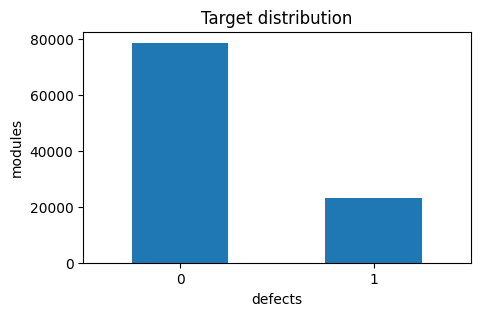

In [5]:
target = data['defects'].astype(int)

print(target.value_counts())
print()
print(target.value_counts(normalize=True).round(4))

target.value_counts().plot(kind='bar', rot=0, figsize=(5, 3),
                           title='Target distribution')
plt.xlabel('defects')
plt.ylabel('modules')
plt.show()

The classes are moderately imbalanced. ROC-AUC is insensitive to this level of skew, so a stratified split is
enough and no resampling is needed.

All features are numeric: Halstead metrics, McCabe metrics and line counters.

## 2. Exploratory analysis

In [6]:
features_raw = data.drop(columns=['id', 'defects'])

skew = features_raw.skew().sort_values(ascending=False)
print('skewness:')
skew.round(2)

skewness:


e                    47.68
t                    46.36
iv(g)                28.21
b                    16.02
lOCode               15.96
v                    15.96
v(g)                 14.26
uniq_Opnd            13.50
lOComment            12.09
loc                  11.82
total_Op             11.15
locCodeAndComment    11.11
total_Opnd           10.50
n                     9.91
lOBlank               8.72
branchCount           8.57
ev(g)                 6.51
uniq_Op               5.64
d                     5.62
i                     4.86
l                     1.90
dtype: float64

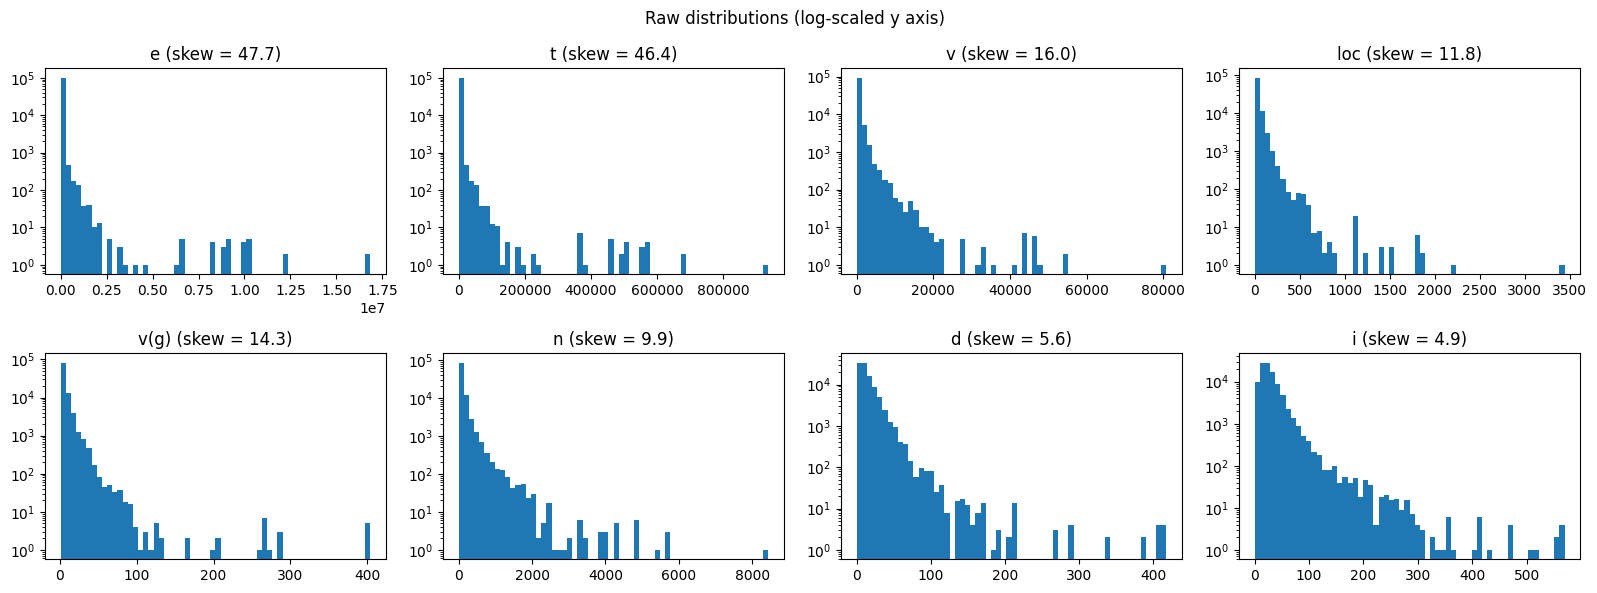

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, ['e', 't', 'v', 'loc', 'v(g)', 'n', 'd', 'i']):
    ax.hist(features_raw[col], bins=60)
    ax.set_title('{} (skew = {:.1f})'.format(col, features_raw[col].skew()))
    ax.set_yscale('log')
plt.suptitle('Raw distributions (log-scaled y axis)')
plt.tight_layout()
plt.show()

The distributions are extremely skewed, with skewness above 40 for some features.

**Idea 1: log-transform the features** (`log1p`). All values are non-negative, and the long tails become manageable.

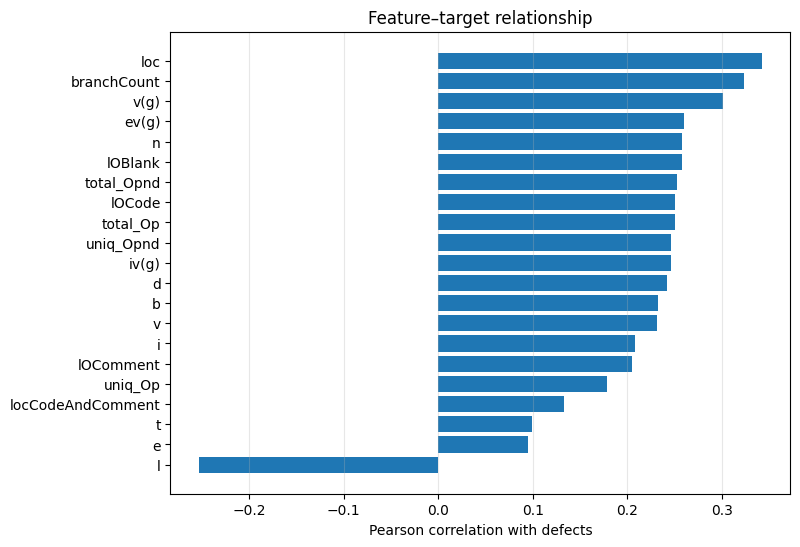

loc                  0.3426
branchCount          0.3228
v(g)                 0.3012
ev(g)                0.2599
n                    0.2581
lOBlank              0.2578
total_Opnd           0.2528
lOCode               0.2506
total_Op             0.2505
uniq_Opnd            0.2461
iv(g)                0.2456
d                    0.2419
b                    0.2326
v                    0.2312
i                    0.2086
lOComment            0.2054
uniq_Op              0.1785
locCodeAndComment    0.1332
t                    0.0996
e                    0.0954
l                   -0.2532
dtype: float64

In [8]:
correlations = features_raw.corrwith(target).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(correlations.index, correlations.values)
plt.xlabel('Pearson correlation with defects')
plt.title('Feature–target relationship')
plt.grid(axis='x', alpha=0.3)
plt.show()

correlations.sort_values(ascending=False).round(4)

### Checking the Halstead formulas

Several Halstead metrics are, by definition, computed from others. If the data follows the formulas, some columns
carry no new information.

In [9]:
eps = 1e-9
identities = {
    'n = total_Op + total_Opnd': (features_raw['total_Op'] + features_raw['total_Opnd'], features_raw['n']),
    'e = v * d': (features_raw['v'] * features_raw['d'], features_raw['e']),
    't = e / 18': (features_raw['e'] / 18, features_raw['t']),
    'b = v / 3000': (features_raw['v'] / 3000, features_raw['b']),
    'l = 1 / d': (1 / (features_raw['d'] + eps), features_raw['l']),
    'i = v / d': (features_raw['v'] / (features_raw['d'] + eps), features_raw['i'])
}

rows = []
for name, (computed, actual) in identities.items():
    rel_error = (computed - actual).abs() / (actual.abs() + eps)
    rows.append({'identity': name,
                 'median_rel_error': rel_error.median(),
                 'share_of_rows_error_below_1%': (rel_error < 0.01).mean()})

pd.DataFrame(rows).round(4)

,identity,median_rel_error,share_of_rows_error_below_1%
0,n = total_Op + total_Opnd,0.0000,0.6644
1,e = v * d,0.0387,0.3221
2,t = e / 18,0.0000,0.9850
3,b = v / 3000,0.0200,0.3461
4,l = 1 / d,0.0256,0.2103
5,i = v / d,0.0295,0.3327


`t = e / 18` holds for almost every row, so `t` duplicates `e`. Other identities hold only partly.

**Idea 2: drop the duplicate feature `t`.**

**Idea 3: add the formula residuals** (`e − v·d`, `n − (total_Op + total_Opnd)`) as features.

### Zeros that are really missing values

In [10]:
halstead = ['n', 'v', 'l', 'd', 'i', 'e', 'b', 't',
            'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd']

zero_mask = (features_raw[halstead] == 0).all(axis=1)

print('rows where every Halstead metric is zero: {} ({:.1%})'.format(
    zero_mask.sum(), zero_mask.mean()))
print()
print('defect rate in these rows:      {:.4f}'.format(target[zero_mask].mean()))
print('defect rate in all other rows:  {:.4f}'.format(target[~zero_mask].mean()))

rows where every Halstead metric is zero: 7692 (7.6%)

defect rate in these rows:      0.4775
defect rate in all other rows:  0.2061


**An important finding.** In 7,692 modules (7.6%) every Halstead metric is zero, yet every one of them has a
non-zero line count (`loc`, median 67). Code with lines but no operators and no operands is impossible, so these
zeros stand for missing values. Their defect
rate is 47.8% against 20.6% in the remaining rows — more than twice as high. The fact that the data is
missing is itself a strong signal.

**Idea 4: add a binary `halstead_missing` flag.**

## 3. Baseline neural network

In [11]:
def split_and_scale(features, target, test_size=0.2, random_state=RANDOM_STATE):
    features_train, features_valid, target_train, target_valid = train_test_split(
        features, target, test_size=test_size,
        random_state=random_state, stratify=target)

    scaler = StandardScaler().fit(features_train)

    return (scaler.transform(features_train), scaler.transform(features_valid),
            target_train.values, target_valid.values)


X_train, X_valid, y_train, y_valid = split_and_scale(features_raw, target)

print('train:     ', X_train.shape)
print('validation:', X_valid.shape)
print('defect rate: train = {:.4f}, valid = {:.4f}'.format(y_train.mean(), y_valid.mean()))

train:      (81410, 21)
validation: (20353, 21)
defect rate: train = 0.2266, valid = 0.2266


In [12]:
def build_model(input_dim, units=(64, 32), dropout=0.0, batchnorm=False,
                learning_rate=1e-3):
    model = keras.Sequential(name='defects_mlp')
    model.add(keras.Input(shape=(input_dim,)))

    for n_units in units:
        model.add(layers.Dense(n_units, use_bias=not batchnorm))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
        if dropout:
            model.add(layers.Dropout(dropout))

    model.add(layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='roc_auc')]
    )
    return model


build_model(X_train.shape[1]).summary()

Model: "defects_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
def train(model, X_train, y_train, X_valid, y_valid, epochs=30,
          batch_size=512, callbacks=None, verbose=0):
    history = model.fit(
        X_train, y_train,
        validation_data=(X_valid, y_valid),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=verbose
    )
    return history


def plot_history(histories, title):
    plt.figure(figsize=(9, 5))
    for name, history in histories.items():
        plt.plot(history.history['val_roc_auc'], label=name)
    plt.xlabel('epoch')
    plt.ylabel('validation ROC-AUC')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

In [14]:
keras.utils.set_random_seed(RANDOM_STATE)

model_base = build_model(X_train.shape[1])
history_base = train(model_base, X_train, y_train, X_valid, y_valid, epochs=30)

best validation ROC-AUC: 0.7908
at the last epoch:       0.7904


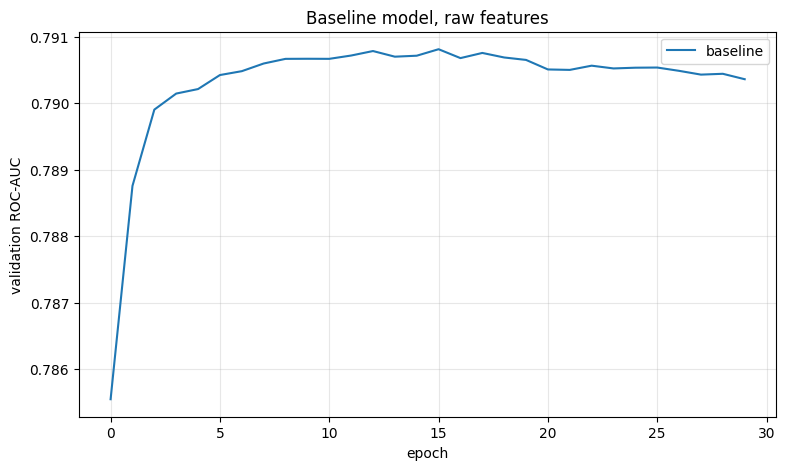

In [15]:
auc_base = max(history_base.history['val_roc_auc'])
print('best validation ROC-AUC: {:.4f}'.format(auc_base))
print('at the last epoch:       {:.4f}'.format(history_base.history['val_roc_auc'][-1]))

plot_history({'baseline': history_base}, 'Baseline model, raw features')

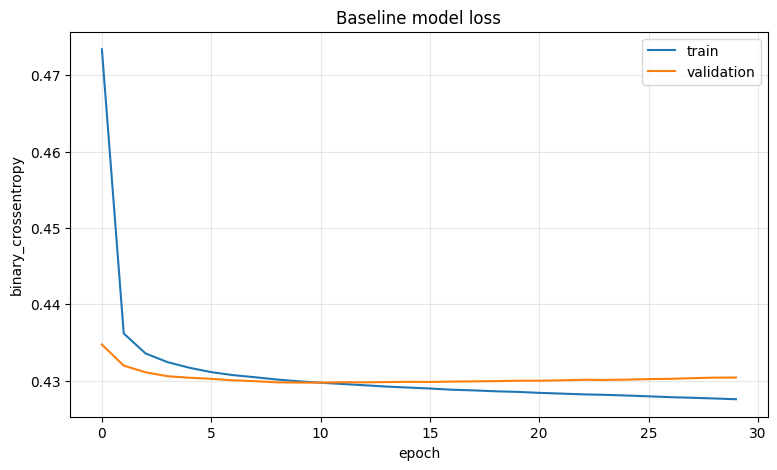

In [16]:
plt.figure(figsize=(9, 5))
plt.plot(history_base.history['loss'], label='train')
plt.plot(history_base.history['val_loss'], label='validation')
plt.xlabel('epoch')
plt.ylabel('binary_crossentropy')
plt.title('Baseline model loss')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Overfitting is already visible: the training loss keeps falling while the validation loss reaches a minimum and
starts to rise.

## 4. Feature experiments

Each idea from the analysis is added one step at a time, and every variant is trained with the same seed and split.

In [17]:
def add_features(features, flag=True, ratios=True, residuals=True, drop_t=True):
    result = features.copy()
    eps = 1e-6

    if flag:
        result['halstead_missing'] = (result[halstead].sum(axis=1) == 0).astype(int)

    if ratios:
        result['comment_ratio'] = (result['lOComment'] + result['locCodeAndComment']) / (result['loc'] + eps)
        result['blank_ratio'] = result['lOBlank'] / (result['loc'] + eps)
        result['code_ratio'] = result['lOCode'] / (result['loc'] + eps)
        result['ops_per_line'] = result['n'] / (result['loc'] + eps)
        result['cc_density'] = result['v(g)'] / (result['loc'] + eps)
        result['branch_per_cc'] = result['branchCount'] / (result['v(g)'] + eps)
        result['ev_ratio'] = result['ev(g)'] / (result['v(g)'] + eps)
        result['iv_ratio'] = result['iv(g)'] / (result['v(g)'] + eps)
        result['vocabulary'] = result['uniq_Op'] + result['uniq_Opnd']
        result['opnd_per_op'] = result['uniq_Opnd'] / (result['uniq_Op'] + eps)
        result['reuse'] = result['total_Opnd'] / (result['uniq_Opnd'] + eps)

    if residuals:
        result['resid_n'] = result['n'] - (result['total_Op'] + result['total_Opnd'])
        result['resid_e'] = np.log1p(result['e'].clip(lower=0)) - np.log1p((result['v'] * result['d']).clip(lower=0))
        result['resid_b'] = result['b'] - result['v'] / 3000

    if drop_t:
        result = result.drop(columns=['t'])

    return result


def log_transform(features):
    return np.log1p(features.clip(lower=0))

In [18]:
def experiment(name, features, epochs=30, seed=RANDOM_STATE, **model_kwargs):
    X_tr, X_va, y_tr, y_va = split_and_scale(features, target)

    keras.utils.set_random_seed(seed)
    model = build_model(X_tr.shape[1], **model_kwargs)
    history = train(model, X_tr, y_tr, X_va, y_va, epochs=epochs)

    best = max(history.history['val_roc_auc'])
    print('{:38s} features: {:3d}   best val ROC-AUC: {:.4f}'.format(
        name, features.shape[1], best))
    return {'variant': name, 'features': features.shape[1],
            'val_roc_auc': best, 'history': history}

In [19]:
experiments = []

experiments.append(experiment('A. raw features', features_raw))
experiments.append(experiment('B. log1p', log_transform(features_raw)))
experiments.append(experiment('C. log1p + halstead_missing',
                              log_transform(add_features(features_raw, ratios=False,
                                                         residuals=False, drop_t=False))))
experiments.append(experiment('D. C + ratio features',
                              log_transform(add_features(features_raw, residuals=False,
                                                         drop_t=False))))
experiments.append(experiment('E. D + Halstead residuals',
                              log_transform(add_features(features_raw, drop_t=False))))
experiments.append(experiment('F. E without feature t',
                              log_transform(add_features(features_raw))))

A. raw features                        features:  21   best val ROC-AUC: 0.7908


B. log1p                               features:  21   best val ROC-AUC: 0.7920


C. log1p + halstead_missing            features:  22   best val ROC-AUC: 0.7923


D. C + ratio features                  features:  33   best val ROC-AUC: 0.7912


E. D + Halstead residuals              features:  36   best val ROC-AUC: 0.7913


F. E without feature t                 features:  35   best val ROC-AUC: 0.7915


In [20]:
comparison = pd.DataFrame([{k: v for k, v in e.items() if k != 'history'}
                           for e in experiments])
comparison['gain_vs_A'] = (comparison['val_roc_auc'] - comparison['val_roc_auc'][0]).round(4)
comparison.round(4)

,variant,features,val_roc_auc,gain_vs_A
0,A. raw features,21,0.7908,0.0000
1,B. log1p,21,0.7920,0.0012
2,C. log1p + halstead_missing,22,0.7923,0.0015
3,D. C + ratio features,33,0.7912,0.0004
4,E. D + Halstead residuals,36,0.7913,0.0005
5,F. E without feature t,35,0.7915,0.0007


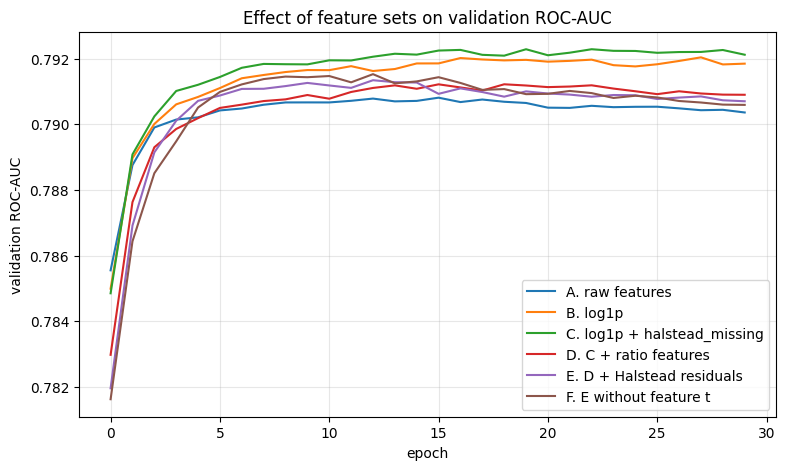

In [21]:
plot_history({e['variant']: e['history'] for e in experiments},
             'Effect of feature sets on validation ROC-AUC')

The final feature set is variant C: `log1p` plus the `halstead_missing` flag. The ratio features and residuals add
columns without a consistent gain.

In [22]:
features_final = log_transform(add_features(features_raw, ratios=False,
                                            residuals=False, drop_t=False))
X_train, X_valid, y_train, y_valid = split_and_scale(features_final, target)

print('final feature count:', X_train.shape[1])
list(features_final.columns)

final feature count: 22


['loc',
 'v(g)',
 'ev(g)',
 'iv(g)',
 'n',
 'v',
 'l',
 'd',
 'i',
 'e',
 'b',
 't',
 'lOCode',
 'lOComment',
 'lOBlank',
 'locCodeAndComment',
 'uniq_Op',
 'uniq_Opnd',
 'total_Op',
 'total_Opnd',
 'branchCount',
 'halstead_missing']

## 5. Regularization

In [23]:
def early_stopping(patience=10):
    return keras.callbacks.EarlyStopping(
        monitor='val_roc_auc',
        mode='max',
        patience=patience,
        restore_best_weights=True
    )


regularization_results = []

for name, kwargs in [
    ('no regularization', {}),
    ('BatchNorm', {'batchnorm': True}),
    ('Dropout 0.3', {'dropout': 0.3}),
    ('BatchNorm + Dropout 0.3', {'batchnorm': True, 'dropout': 0.3})
]:
    keras.utils.set_random_seed(RANDOM_STATE)
    model = build_model(X_train.shape[1], **kwargs)
    history = train(model, X_train, y_train, X_valid, y_valid,
                    epochs=60, callbacks=[early_stopping()])

    best = max(history.history['val_roc_auc'])
    regularization_results.append({'variant': name, 'epochs_trained': len(history.history['loss']),
                                   'val_roc_auc': best, 'history': history})
    print('{:26s} epochs: {:3d}   best val ROC-AUC: {:.4f}'.format(
        name, len(history.history['loss']), best))

no regularization          epochs:  33   best val ROC-AUC: 0.7923


BatchNorm                  epochs:  18   best val ROC-AUC: 0.7925


Dropout 0.3                epochs:  60   best val ROC-AUC: 0.7925


BatchNorm + Dropout 0.3    epochs:  28   best val ROC-AUC: 0.7920


In [24]:
pd.DataFrame([{k: v for k, v in r.items() if k != 'history'}
              for r in regularization_results]).round(4)

,variant,epochs_trained,val_roc_auc
0,no regularization,33,0.7923
1,BatchNorm,18,0.7925
2,Dropout 0.3,60,0.7925
3,BatchNorm + Dropout 0.3,28,0.7920


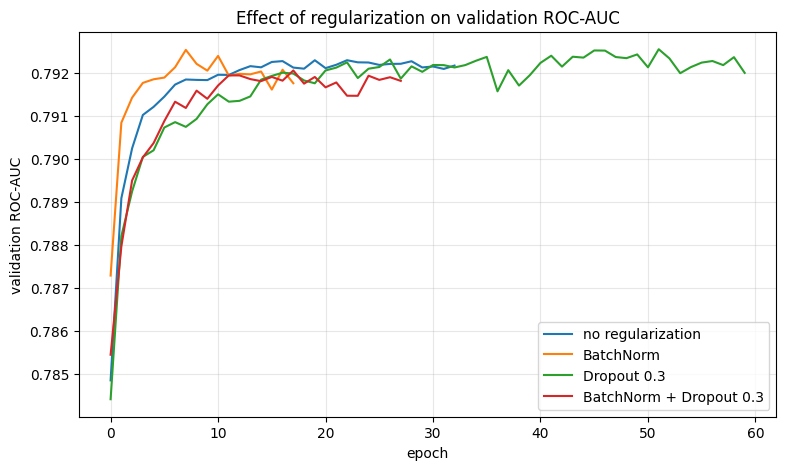

In [25]:
plot_history({r['variant']: r['history'] for r in regularization_results},
             'Effect of regularization on validation ROC-AUC')

## 6. Final model

A wider 256-128-64 network with BatchNorm and Dropout, early stopping on validation ROC-AUC, and a checkpoint that
keeps the best epoch's weights on disk.

In [26]:
CHECKPOINT_PATH = 'best_defects_model.keras'

checkpoint = keras.callbacks.ModelCheckpoint(
    CHECKPOINT_PATH,
    monitor='val_roc_auc',
    mode='max',
    save_best_only=True,
    verbose=0
)

keras.utils.set_random_seed(RANDOM_STATE)
model_final = build_model(X_train.shape[1], units=(256, 128, 64),
                          dropout=0.3, batchnorm=True)
model_final.summary()

Model: "defects_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                │ (None, 256)            │         5,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_24 (Activation)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_25 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_26 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,449 (189.25 KB)

 Trainable params: 47,553 (185.75 KB)

 Non-trainable params: 896 (3.50 KB)

In [27]:
history_final = train(model_final, X_train, y_train, X_valid, y_valid,
                      epochs=100,
                      callbacks=[early_stopping(patience=12), checkpoint])

best_epoch = int(np.argmax(history_final.history['val_roc_auc'])) + 1
print('training stopped at epoch:', len(history_final.history['loss']))
print('best epoch:', best_epoch)
print('best val ROC-AUC: {:.4f}'.format(max(history_final.history['val_roc_auc'])))

training stopped at epoch: 42
best epoch: 30
best val ROC-AUC: 0.7933


In [28]:
saved_model = keras.models.load_model(CHECKPOINT_PATH)
predictions = saved_model.predict(X_valid, verbose=0).ravel()
auc_final = roc_auc_score(y_valid, predictions)

print('checkpoint file:', CHECKPOINT_PATH, '({:.1f} KB)'.format(
    os.path.getsize(CHECKPOINT_PATH) / 1024))
print('saved model, validation ROC-AUC: {:.4f}'.format(auc_final))
print('baseline model, ROC-AUC:         {:.4f}'.format(auc_base))
print('gain: {:+.4f}'.format(auc_final - auc_base))

checkpoint file: best_defects_model.keras (618.6 KB)
saved model, validation ROC-AUC: 0.7934
baseline model, ROC-AUC:         0.7908
gain: +0.0026


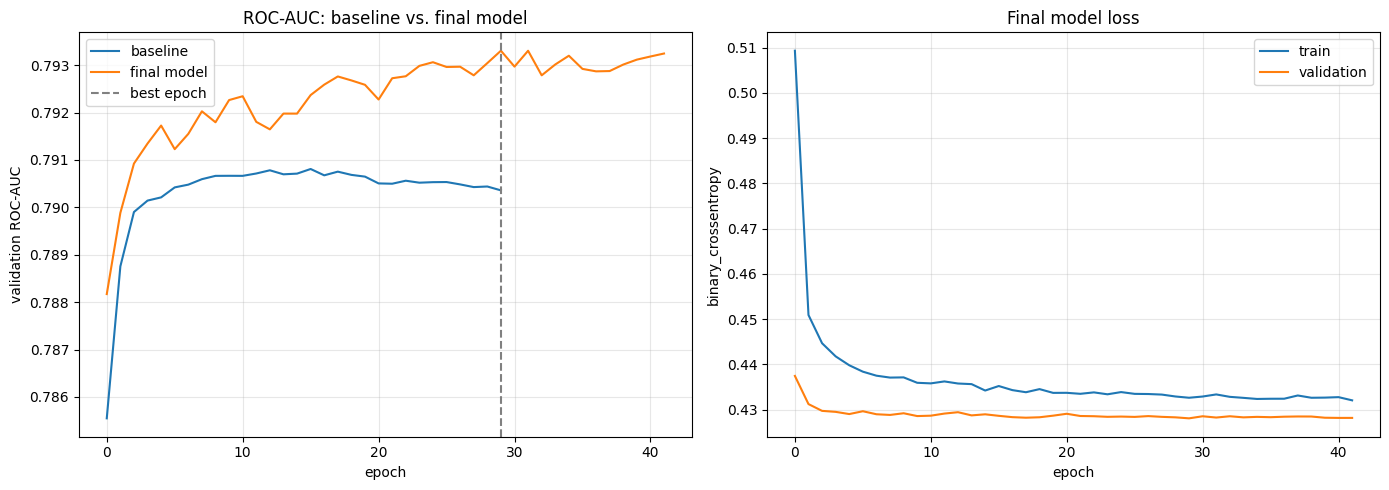

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_base.history['val_roc_auc'], label='baseline')
axes[0].plot(history_final.history['val_roc_auc'], label='final model')
axes[0].axvline(best_epoch - 1, ls='--', color='gray', label='best epoch')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('validation ROC-AUC')
axes[0].set_title('ROC-AUC: baseline vs. final model')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(history_final.history['loss'], label='train')
axes[1].plot(history_final.history['val_loss'], label='validation')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('binary_crossentropy')
axes[1].set_title('Final model loss')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Conclusions

**Best result: validation ROC-AUC 0.7934.** A 256-128-64 network with BatchNorm and Dropout 0.3 on 22 features
(`log1p` plus the `halstead_missing` flag); the best epoch's weights are saved in `best_defects_model.keras`.
The baseline network on raw features scored 0.7908, so all the work added **+0.0026**.

**Features.**

* The log transform was the largest single step: 0.7908 → 0.7920 (+0.0012). Some features had skewness above 40.
* The `halstead_missing` flag added a little more (0.7923). Its value is mainly analytical: modules with unfilled
  metrics are defective 47.8% of the time against 20.6% for the rest, which is worth reporting whatever the model
  does with it. The network gains little from the flag most likely because the all-zero pattern is already visible
  in the raw columns.
* Ratio features and formula residuals made things **worse**, not better (0.7912–0.7915 against 0.7923), and dropping
  the duplicate `t` did not recover the difference. More columns did not mean more signal.

**Regularization.** On the 64-32 network the differences are within a few ten-thousandths: BatchNorm and Dropout
both reach 0.7925 against 0.7923 without regularization, and combining them gives 0.7920. BatchNorm reaches its best
score fastest (early stopping after 18 epochs). Early stopping and checkpointing do not raise the score, but they stop
training on a plateau and keep the best weights: the final model stopped at epoch 42 and kept epoch 30.

**Why the ceiling is 0.79.** Halstead and McCabe metrics measure the size and branching of code, not what it does.
That limits any model trained on them, so the gap between a naive and a carefully tuned network is measured in the
third decimal place.

**Limitation.** Every comparison uses one validation split, and the final model is both selected and scored on it.
Differences of 0.001–0.003 are small enough that another seed or split could reorder the variants. Claiming that the
tuned model is genuinely better would need repeated cross-validation or a separate test set.